# Track 2 · Beginner: Portfolio Selection with QAOA

**Qiskit Fall Fest 2026 · IIIT-Delhi · Track 2 (Quantum Optimization)**
Team: _<team name / members>_ · Level reached: **Beginner**

**Goal.** Choose exactly **K = 3 of n = 6 stocks** that maximize expected return while penalizing risk, using the
Quantum Approximate Optimization Algorithm (QAOA), and check every result against brute force.

**What this notebook delivers (the Beginner checklist)**
1. The portfolio cost $C(x)$ turned into a Pauli operator, verified bitstring-by-bitstring against brute force.
2. QAOA solved on a noiseless simulator, with the answer checked against the brute-force optimum (20 valid portfolios).
3. **Approximation ratio $r$ vs depth $p = 1 \dots 4$.**
4. **Penalty sweep:** fraction of samples that buy exactly $K$ stocks vs $\lambda$; how small $\lambda$ can go; how often QAOA returns the single best portfolio.
5. Hardware awareness: transpiled depth on a real IBM device layout and a noisy simulation (free, no QPU time), plus an opt-in cell for one real-hardware run.

Runs top to bottom on Google Colab in a few minutes. No IBM account is needed unless you switch on the hardware cell.

## 0. Setup

In [1]:
# Installs Qiskit on Colab if it's missing (already-installed environments skip this)
try:
    import qiskit, qiskit_aer, qiskit_ibm_runtime
except ImportError:
    %pip install -q qiskit qiskit-aer qiskit-ibm-runtime

In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import qiskit
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", module="scipy")

# Chart style: thin lines, recessive grid, colour-blind-safe pair (blue / orange)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 8,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 11,
})
print("Qiskit", qiskit.__version__)

Qiskit 2.5.2


## 1. The problem and the shared data

The data below is copied exactly from the challenge README, so every team works on the same instance.

$x_i = 1$ means "buy stock $i$". The cost to **minimize** is

$$C(x) = q\, x^{\top} \Sigma\, x \;-\; \mu^{\top} x \;+\; \lambda \Big( \sum_i x_i - K \Big)^2$$

- $q\,x^\top\Sigma x$ is the portfolio **risk** (variance), weighted by risk aversion $q$.
- $-\mu^\top x$ rewards expected **return**.
- $\lambda(\sum x_i - K)^2$ is the **budget penalty**: zero when exactly $K$ stocks are bought, positive otherwise.

In [3]:
rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5               # stocks, pick exactly K, risk aversion
mu = rng.uniform(0.05, 0.25, n)   # expected returns
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T                   # covariance (risk)

pd.DataFrame({"expected return μ": mu.round(4), "variance Σ_ii": np.diag(sigma).round(4)},
             index=[f"stock {i}" for i in range(n)])

,expected return μ,variance Σ_ii
stock 0,0.0858,0.0110
stock 1,0.1780,0.0088
stock 2,0.1435,0.0264
stock 3,0.1241,0.0761
stock 4,0.1210,0.0644
stock 5,0.2081,0.0194


## 2. Classical reference: brute force

With 6 stocks there are $2^6 = 64$ possible portfolios, of which $\binom{6}{3} = 20$ obey the budget.
We score all of them. This is the **exact answer** every quantum result is checked against.

**Bit convention (used throughout).** Bitstring index $k$ maps to $x_i = $ bit $i$ of $k$, which is how Qiskit
orders qubits (qubit 0 is the rightmost character of a measured string).

In [4]:
def bits_of(k):
    # integer k -> portfolio vector x, with x[i] = bit i of k (= qubit i)
    return np.array([(k >> i) & 1 for i in range(n)])

def stocks(x):
    return tuple(int(i) for i in np.flatnonzero(x))   # indices of stocks bought

def portfolio_cost(x, lam):
    x = np.asarray(x)
    return q * x @ sigma @ x - mu @ x + lam * (x.sum() - K) ** 2

ALL_X = [bits_of(k) for k in range(2 ** n)]
FEASIBLE = [x for x in ALL_X if x.sum() == K]

# For feasible portfolios the penalty is zero, so this ranking does not depend on λ
ranked = sorted(FEASIBLE, key=lambda x: portfolio_cost(x, 0.0))
BEST_X = ranked[0]
BEST_COST = portfolio_cost(BEST_X, 0.0)

table = pd.DataFrame([{
    "stocks bought": stocks(x),
    "expected return μᵀx": round(float(mu @ x), 4),
    "risk q·xᵀΣx": round(float(q * x @ sigma @ x), 4),
    "cost C(x)": round(float(portfolio_cost(x, 0.0)), 4),
} for x in ranked])
print(f"{len(FEASIBLE)} valid portfolios. Best: stocks {stocks(BEST_X)}, cost {BEST_COST:.4f}")
table.head(5)

20 valid portfolios. Best: stocks (1, 2, 5), cost -0.5030


,stocks bought,expected return μᵀx,risk q·xᵀΣx,cost C(x)
0,"(1, 2, 5)",0.5295,0.0265,-0.5030
1,"(1, 3, 5)",0.5102,0.0315,-0.4787
2,"(0, 1, 5)",0.4719,0.0074,-0.4645
3,"(1, 4, 5)",0.5071,0.0474,-0.4597
4,"(2, 3, 5)",0.4757,0.0536,-0.4221


### How large must the penalty be?

With $\lambda = 0$ the cheapest portfolio buys **everything** (more stocks = more return here). As $\lambda$ grows,
breaking the budget gets expensive. We find the smallest $\lambda^*$ for which the overall cheapest bitstring
obeys the budget. Below $\lambda^*$ even a *perfect* solver would return an invalid portfolio.

In [5]:
def global_min_x(lam):
    costs = np.array([portfolio_cost(x, lam) for x in ALL_X])
    return ALL_X[int(costs.argmin())]

for lam in [0.0, 0.05, 0.10, 0.15]:
    x = global_min_x(lam)
    print(f"λ = {lam:4.2f}: cheapest bitstring buys {x.sum()} stocks {stocks(x)}")

lo, hi = 0.0, 1.0                    # bisection for the threshold λ*
for _ in range(50):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if global_min_x(mid).sum() == K else (mid, hi)
LAMBDA_STAR = hi
print(f"\nThreshold λ* ≈ {LAMBDA_STAR:.4f}")

λ = 0.00: cheapest bitstring buys 6 stocks (0, 1, 2, 3, 4, 5)
λ = 0.05: cheapest bitstring buys 4 stocks (1, 2, 3, 5)
λ = 0.10: cheapest bitstring buys 4 stocks (1, 2, 3, 5)
λ = 0.15: cheapest bitstring buys 3 stocks (1, 2, 5)

Threshold λ* ≈ 0.1097


## 3. Encoding: from $C(x)$ to a Pauli operator

**Step 1 — QUBO form.** Using $x_i^2 = x_i$ (binary variables), expand $C(x)$ into linear terms $h_i x_i$,
pair terms $Q_{ij} x_i x_j$ ($i<j$) and a constant:

$$h_i = q\Sigma_{ii} - \mu_i + \lambda(1 - 2K), \qquad Q_{ij} = 2q\Sigma_{ij} + 2\lambda, \qquad c_0 = \lambda K^2$$

**Step 2 — Spin substitution.** Replace $x_i = (1 - Z_i)/2$:

$$x_i \to \tfrac12 - \tfrac12 Z_i, \qquad x_i x_j \to \tfrac14\big(1 - Z_i - Z_j + Z_i Z_j\big)$$

This gives single-$Z$ terms (return and own-risk), $ZZ$ terms (covariance and penalty) and an identity term (constant).
Unlike Max-Cut, we **keep the constant**, so the operator's energy equals the real portfolio cost.

In [6]:
def qubo(lam):
    h = np.array([q * sigma[i, i] - mu[i] + lam * (1 - 2 * K) for i in range(n)])
    Q = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            Q[i, j] = 2 * q * sigma[i, j] + 2 * lam
    return h, Q, lam * K ** 2

def z_label(*qubits):
    s = ["I"] * n
    for k in qubits:
        s[k] = "Z"
    return "".join(reversed(s))      # Qiskit: qubit 0 is the rightmost character

def portfolio_hamiltonian(lam):
    h, Q, const = qubo(lam)
    terms = {}
    def add(label, v):
        terms[label] = terms.get(label, 0.0) + v
    for i in range(n):
        const += h[i] / 2
        add(z_label(i), -h[i] / 2)
        for j in range(i + 1, n):
            const += Q[i, j] / 4
            add(z_label(i), -Q[i, j] / 4)
            add(z_label(j), -Q[i, j] / 4)
            add(z_label(i, j), Q[i, j] / 4)
    add("I" * n, const)
    return SparsePauliOp.from_list(list(terms.items())).simplify()

H_demo = portfolio_hamiltonian(0.15)
print(f"{len(H_demo)} terms: 1 identity + {n} single-Z + {n*(n-1)//2} ZZ")
print(H_demo)

22 terms: 1 identity + 6 single-Z + 15 ZZ
SparsePauliOp(['IIIIIZ', 'IIIIZI', 'IIIIZZ', 'IIIZII', 'IIIZIZ', 'IIZIII', 'IIZIIZ', 'IZIIII', 'IZIIIZ', 'ZIIIII', 'ZIIIIZ', 'IIIZZI', 'IIZIZI', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII', 'IIIIII'],
              coeffs=[ 0.04413445+0.j,  0.09052456+0.j,  0.07520285+0.j,  0.07078699+0.j,
  0.07339676+0.j,  0.04065603+0.j,  0.07361213+0.j,  0.03553186+0.j,
  0.07502482+0.j,  0.09953255+0.j,  0.07378316+0.j,  0.07414527+0.j,
  0.07363211+0.j,  0.07531986+0.j,  0.07297183+0.j,  0.07223449+0.j,
  0.07187009+0.j,  0.07769049+0.j,  0.08465842+0.j,  0.07322937+0.j,
  0.07699455+0.j, -0.15493265+0.j])


**Verification.** All terms are $Z$/$I$ only, so the operator is a diagonal $64 \times 64$ matrix whose
$k$-th diagonal entry should equal $C(\text{bits of }k)$. We check this for several values of $\lambda$.

In [7]:
for lam in [0.0, 0.15, 1.0]:
    diag = np.real(np.diag(portfolio_hamiltonian(lam).to_matrix()))
    brute = np.array([portfolio_cost(x, lam) for x in ALL_X])
    err = np.abs(diag - brute).max()
    print(f"λ = {lam:4.2f}: max |operator − brute force| over 64 bitstrings = {err:.1e}")
    assert err < 1e-10
print("Encoding verified.")

λ = 0.00: max |operator − brute force| over 64 bitstrings = 2.2e-16
λ = 0.15: max |operator − brute force| over 64 bitstrings = 2.8e-16
λ = 1.00: max |operator − brute force| over 64 bitstrings = 2.2e-15
Encoding verified.


## 4. The QAOA solver

Same workflow as the Max-Cut tutorial, with four changes:

- **Normalization.** We split $H = c_0 I + H_Z$ and run QAOA on $H_Z / s$, where $s$ is the largest coefficient.
  The best bitstring is unchanged, but the angle landscape no longer depends on the size of $\lambda$.
  Energies are converted back with $\langle C \rangle = s\,\langle H_Z/s \rangle + c_0$.
- **Transpile once** before the optimizer loop (the README's tip): evaluations get much faster.
- **Multi-start COBYLA**, keeping the best run, because a single start often stalls in a poor local minimum.
- **Layer-by-layer warm start** for $p \ge 2$: start from the best $p-1$ angles with the last layer repeated
  (an interpolation strategy from Zhou et al., PRX 2020), plus random starts.

Qiskit orders the QAOA parameters as $[\beta_0 \dots \beta_{p-1}, \gamma_0 \dots \gamma_{p-1}]$.

In [8]:
SEED = 7
estimator = StatevectorEstimator()
sampler = StatevectorSampler(seed=SEED)

def split_hamiltonian(lam):
    H = portfolio_hamiltonian(lam)
    labels = H.paulis.to_labels()
    offset = float(np.real(sum(c for l, c in zip(labels, H.coeffs) if l == "I" * n)))
    HZ = SparsePauliOp.from_list([(l, c) for l, c in zip(labels, H.coeffs) if l != "I" * n])
    scale = float(np.max(np.abs(HZ.coeffs)))
    return HZ / scale, scale, offset

def extend_angles(theta):
    # p-1 angles [β..., γ...] -> p angles by repeating the last layer
    half = len(theta) // 2
    b, g = theta[:half], theta[half:]
    return np.concatenate([np.append(b, b[-1]), np.append(g, g[-1])])

def solve_qaoa(lam, p, n_starts=8, warm=None, seed=0, maxiter=300):
    H_norm, scale, offset = split_hamiltonian(lam)
    ansatz = transpile(QAOAAnsatz(H_norm, reps=p),
                       basis_gates=["h", "rx", "rz", "rzz"], optimization_level=1)

    def energy(theta):
        return float(estimator.run([(ansatz, H_norm, theta)]).result()[0].data.evs)

    rng_ = np.random.default_rng(seed)
    starts = ([warm] if warm is not None else []) + \
             [rng_.uniform(0, np.pi, 2 * p) for _ in range(n_starts)]
    best = None
    for x0 in starts:
        trial = minimize(energy, x0, method="COBYLA", options={"maxiter": maxiter})
        if best is None or trial.fun < best.fun:
            best = trial
    return {"theta": best.x, "mean_cost": best.fun * scale + offset, "ansatz": ansatz}

def key_to_x(key):
    return np.array([int(b) for b in key.replace(" ", "")[::-1]])   # reverse: index 0 = stock 0

def sample(ansatz, theta, shots=4096, run_sampler=None):
    circ = ansatz.assign_parameters(theta)
    circ.measure_all()
    run_sampler = run_sampler or sampler
    counts = run_sampler.run([circ], shots=shots).result()[0].data.meas.get_counts()
    return circ, counts

def summarize(counts, lam):
    shots = sum(counts.values())
    p_feas = sum(c for k, c in counts.items() if key_to_x(k).sum() == K) / shots
    p_opt = sum(c for k, c in counts.items() if np.array_equal(key_to_x(k), BEST_X)) / shots
    top_x = key_to_x(max(counts, key=counts.get))
    best_seen = min(counts, key=lambda k: portfolio_cost(key_to_x(k), lam))
    return {"P(feasible)": p_feas, "P(best portfolio)": p_opt,
            "most sampled": stocks(top_x),
            "most sampled valid?": bool(top_x.sum() == K),
            "most sampled = best?": bool(np.array_equal(top_x, BEST_X)),
            "best sampled cost": portfolio_cost(key_to_x(best_seen), lam)}

## 5. Approximation ratio vs depth $p$

The README's metric uses the **average** cost of the QAOA state, so it reflects the whole output distribution,
not just the luckiest sample:

$$r = \frac{C_{\max} - \langle C \rangle}{C_{\max} - C_{\min}}, \qquad r = 1 \text{ is perfect}$$

$C_{\max}$ and $C_{\min}$ are taken over all $2^n$ bitstrings. We fix $\lambda = 0.15$, just above $\lambda^*$
(the penalty sweep in Section 6 shows why this region is the sweet spot).

In [9]:
LAM = 0.15
all_costs = np.array([portfolio_cost(x, LAM) for x in ALL_X])
C_MAX, C_MIN = all_costs.max(), all_costs.min()

depth_rows, depth_runs, warm = [], {}, None
t0 = time.time()
for p in range(1, 5):
    run = solve_qaoa(LAM, p, warm=warm, seed=p)
    warm = extend_angles(run["theta"])
    circ, counts = sample(run["ansatz"], run["theta"])
    depth_runs[p] = {**run, "circuit": circ, "counts": counts}
    r = (C_MAX - run["mean_cost"]) / (C_MAX - C_MIN)
    depth_rows.append({"p": p, "⟨C⟩": round(run["mean_cost"], 4), "r": round(r, 4),
                       **summarize(counts, LAM),
                       "2-qubit gates": circ.count_ops().get("rzz", 0)})
    print(f"p = {p} done ({time.time() - t0:.0f}s)")

depth_df = pd.DataFrame(depth_rows).set_index("p")
depth_df.round(4)

p = 1 done (2s)


p = 2 done (12s)


p = 3 done (33s)


p = 4 done (60s)


,⟨C⟩,r,P(feasible),P(best portfolio),most sampled,most sampled valid?,most sampled = best?,best sampled cost,2-qubit gates
p,,,,,,,,,
1,-0.3505,0.9177,0.5688,0.0361,"(1, 2, 5)",True,True,-0.503,15
2,-0.4082,0.9488,0.5295,0.4287,"(1, 2, 5)",True,True,-0.503,30
3,-0.4277,0.9594,0.6997,0.5488,"(1, 2, 5)",True,True,-0.503,45
4,-0.4329,0.9622,0.6531,0.5286,"(1, 2, 5)",True,True,-0.503,60


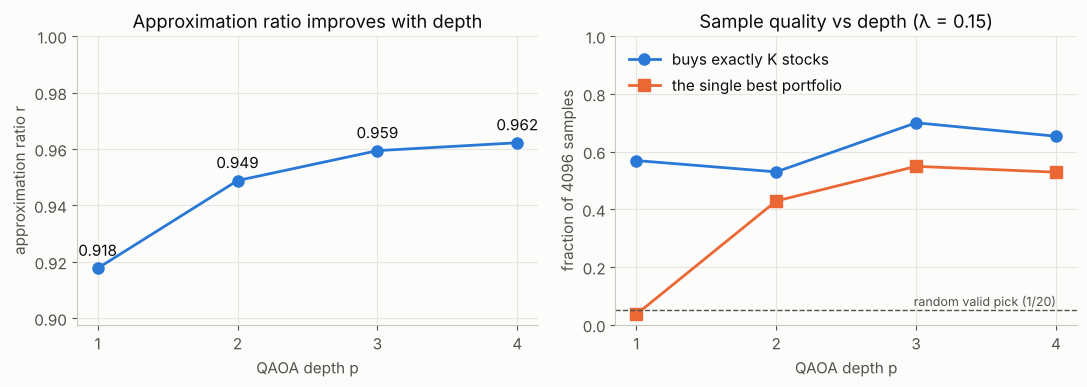

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ps = depth_df.index

ax1.plot(ps, depth_df["r"], "o-", color=BLUE)
for p, r in zip(ps, depth_df["r"]):
    ax1.annotate(f"{r:.3f}", (p, r), textcoords="offset points", xytext=(0, 9), ha="center", color=INK)
ax1.set(xlabel="QAOA depth p", ylabel="approximation ratio r", xticks=list(ps),
        title="Approximation ratio improves with depth")
ax1.set_ylim(depth_df["r"].min() - 0.02, 1.0)

ax2.plot(ps, depth_df["P(feasible)"], "o-", color=BLUE, label="buys exactly K stocks")
ax2.plot(ps, depth_df["P(best portfolio)"], "s-", color=ORANGE, label="the single best portfolio")
ax2.axhline(1 / len(FEASIBLE), color=MUTED, lw=1, ls="--")
ax2.text(4, 1 / len(FEASIBLE) + 0.015, "random valid pick (1/20)", ha="right", color=MUTED, fontsize=9)
ax2.set(xlabel="QAOA depth p", ylabel="fraction of 4096 samples", xticks=list(ps), ylim=(0, 1),
        title=f"Sample quality vs depth (λ = {LAM})")
ax2.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

### Check against brute force

In [11]:
for p, run in depth_runs.items():
    best_key = min(run["counts"], key=lambda k: portfolio_cost(key_to_x(k), LAM))
    found = key_to_x(best_key)
    print(f"p = {p}: best sampled portfolio {stocks(found)}, "
          f"cost {portfolio_cost(found, LAM):.4f}  |  brute force {stocks(BEST_X)}, "
          f"cost {BEST_COST:.4f}  ->  {'MATCH' if np.array_equal(found, BEST_X) else 'differs'}")

p = 1: best sampled portfolio (1, 2, 5), cost -0.5030  |  brute force (1, 2, 5), cost -0.5030  ->  MATCH
p = 2: best sampled portfolio (1, 2, 5), cost -0.5030  |  brute force (1, 2, 5), cost -0.5030  ->  MATCH
p = 3: best sampled portfolio (1, 2, 5), cost -0.5030  |  brute force (1, 2, 5), cost -0.5030  ->  MATCH
p = 4: best sampled portfolio (1, 2, 5), cost -0.5030  |  brute force (1, 2, 5), cost -0.5030  ->  MATCH


## 6. Penalty sweep: how $\lambda$ decides whether answers obey the budget

We rerun QAOA at fixed depth $p = 2$ for a range of $\lambda$ and record, from 4096 samples:
the fraction that buy exactly $K$ stocks, how often the single best portfolio appears, and whether QAOA's
most-sampled answer is valid.

In [12]:
P_SWEEP = 2
LAMBDAS = [0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.30, 0.50, 1.0, 2.0]

sweep_rows = []
t0 = time.time()
for lam in LAMBDAS:
    p1 = solve_qaoa(lam, 1, n_starts=6, seed=11)
    run = solve_qaoa(lam, P_SWEEP, n_starts=6, warm=extend_angles(p1["theta"]), seed=12)
    _, counts = sample(run["ansatz"], run["theta"])
    sweep_rows.append({"λ": lam, **summarize(counts, lam)})
print(f"sweep done ({time.time() - t0:.0f}s)")

sweep_df = pd.DataFrame(sweep_rows).set_index("λ")
sweep_df.round(3)

sweep done (126s)


,P(feasible),P(best portfolio),most sampled,most sampled valid?,most sampled = best?,best sampled cost
λ,,,,,,
0.02,0.012,0.005,"(0, 1, 2, 3, 4, 5)",False,False,-0.629
0.05,0.087,0.042,"(1, 2, 3, 5)",False,False,-0.563
0.08,0.535,0.005,"(1, 4, 5)",True,False,-0.533
0.10,0.412,0.220,"(1, 2, 5)",True,True,-0.513
0.12,0.719,0.537,"(1, 2, 5)",True,True,-0.503
0.15,0.530,0.429,"(1, 2, 5)",True,True,-0.503
0.20,0.662,0.042,"(1, 2, 5)",True,True,-0.503
0.30,0.809,0.041,"(1, 4, 5)",True,False,-0.503
0.50,0.914,0.046,"(0, 2, 4)",True,False,-0.503


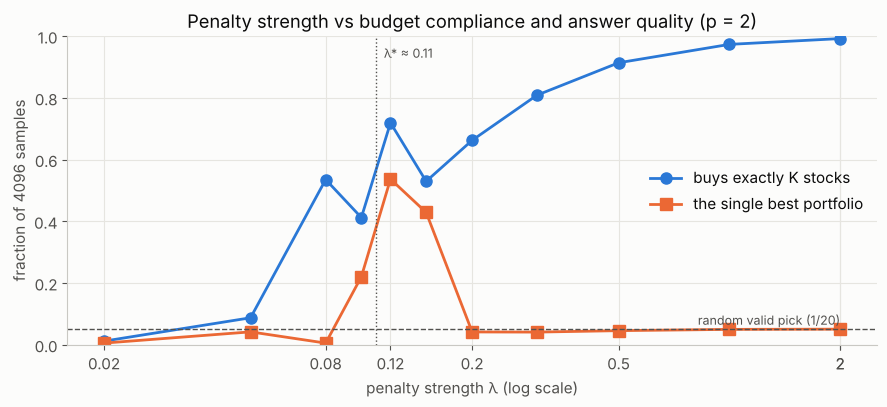

Smallest λ tested where QAOA's most-sampled answer obeys the budget: 0.08
λ values where QAOA's most-sampled answer IS the best portfolio: [0.1, 0.12, 0.15, 0.2]
Best portfolio is sampled most often at λ = 0.12 (53.7% of shots)


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(sweep_df.index, sweep_df["P(feasible)"], "o-", color=BLUE, label="buys exactly K stocks")
ax.plot(sweep_df.index, sweep_df["P(best portfolio)"], "s-", color=ORANGE, label="the single best portfolio")
ax.axvline(LAMBDA_STAR, color=MUTED, lw=1, ls=":")
ax.text(LAMBDA_STAR * 1.05, 0.93, f"λ* ≈ {LAMBDA_STAR:.2f}", color=MUTED, fontsize=9)
ax.axhline(1 / len(FEASIBLE), color=MUTED, lw=1, ls="--")
ax.text(2.0, 1 / len(FEASIBLE) + 0.015, "random valid pick (1/20)", ha="right", color=MUTED, fontsize=9)
ax.set_xscale("log")
ax.set_xticks(LAMBDAS[::2] + [LAMBDAS[-1]], [f"{l:g}" for l in LAMBDAS[::2] + [LAMBDAS[-1]]])
ax.minorticks_off()
ax.set(xlabel="penalty strength λ (log scale)", ylabel="fraction of 4096 samples", ylim=(0, 1),
       title=f"Penalty strength vs budget compliance and answer quality (p = {P_SWEEP})")
ax.legend(frameon=False, loc="center right")
plt.tight_layout(); plt.show()

valid_top = sweep_df[sweep_df["most sampled valid?"]]
print(f"Smallest λ tested where QAOA's most-sampled answer obeys the budget: {valid_top.index.min()}")
best_top = sweep_df[sweep_df["most sampled = best?"]].index
print(f"λ values where QAOA's most-sampled answer IS the best portfolio: {list(best_top)}")
best_lam = sweep_df["P(best portfolio)"].idxmax()
print(f"Best portfolio is sampled most often at λ = {best_lam} "
      f"({sweep_df.loc[best_lam, 'P(best portfolio)']:.1%} of shots)")

## 7. Hardware awareness (free): real device layout and noise

Real IBM chips connect each qubit to only 2–3 neighbours (heavy-hex), and every pair of stocks has a
covariance term. So the transpiler must insert SWAPs, which deepens the circuit. We transpile the $p = 2$
circuit for **FakeSherbrooke**, a local copy of a real 127-qubit IBM device's layout and noise model, compare
optimization levels, and run a **noisy simulation**. None of this uses QPU time.

In [14]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit_ibm_runtime import SamplerV2

fake = FakeSherbrooke()
circ_p2 = depth_runs[2]["circuit"]

layout_rows, transpiled = [], {}
for level in [1, 2, 3]:
    pm = generate_preset_pass_manager(optimization_level=level, backend=fake, seed_transpiler=1)
    tc = pm.run(circ_p2)
    transpiled[level] = tc
    ops = tc.count_ops()
    layout_rows.append({"optimization level": level, "depth": tc.depth(),
                        "2-qubit gates (ECR)": ops.get("ecr", 0),
                        "physical qubits": sorted(tc.layout.final_index_layout())})
print(f"Logical circuit: {circ_p2.count_ops().get('rzz', 0)} RZZ gates "
      f"({n*(n-1)//2} stock pairs × {2} layers)")
pd.DataFrame(layout_rows).set_index("optimization level")

Logical circuit: 30 RZZ gates (15 stock pairs × 2 layers)


,depth,2-qubit gates (ECR),physical qubits
optimization level,,,
1,335,135,"[121, 122, 123, 124, 125, 126]"
2,378,113,"[41, 53, 58, 59, 60, 61]"
3,378,113,"[41, 53, 58, 59, 60, 61]"


In [15]:
best_level = min(transpiled, key=lambda l: transpiled[l].count_ops().get("ecr", 0))
noisy_sampler = SamplerV2(mode=fake, options={"simulator": {"seed_simulator": SEED}})
noisy_counts = noisy_sampler.run([transpiled[best_level]], shots=4096).result()[0].data.meas.get_counts()

noiseless = summarize(depth_runs[2]["counts"], LAM)
noisy = summarize(noisy_counts, LAM)
compare = pd.DataFrame({"noiseless (statevector)": noiseless, "noisy (FakeSherbrooke)": noisy}).T
compare[["P(feasible)", "P(best portfolio)", "most sampled", "most sampled = best?"]]

,P(feasible),P(best portfolio),most sampled,most sampled = best?
noiseless (statevector),0.529541,0.428711,"(1, 2, 5)",True
noisy (FakeSherbrooke),0.430176,0.240234,"(1, 2, 5)",True


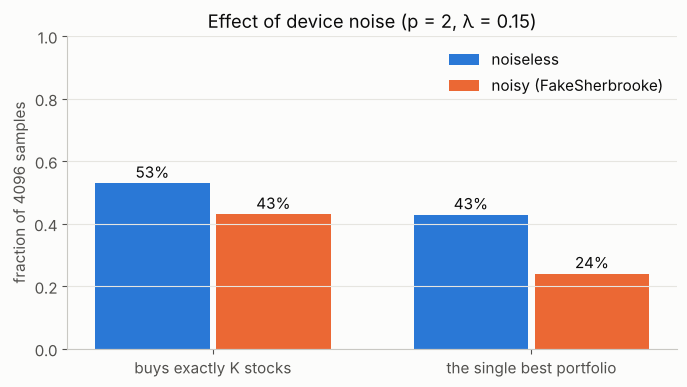

In [16]:
metrics = ["P(feasible)", "P(best portfolio)"]
xpos = np.arange(len(metrics)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(xpos - w/2 - 0.01, [noiseless[m] for m in metrics], w, color=BLUE, label="noiseless")
b2 = ax.bar(xpos + w/2 + 0.01, [noisy[m] for m in metrics], w, color=ORANGE, label="noisy (FakeSherbrooke)")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{b.get_height():.0%}", (b.get_x() + b.get_width()/2, b.get_height()),
                    textcoords="offset points", xytext=(0, 4), ha="center", color=INK)
ax.set_xticks(xpos, ["buys exactly K stocks", "the single best portfolio"])
ax.set(ylabel="fraction of 4096 samples", ylim=(0, 1), title="Effect of device noise (p = 2, λ = 0.15)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. Optional: one run on a real IBM QPU

Off by default. Free accounts get **10 QPU minutes per 28 days**, so this sends **one** sampling job with the
angles already optimized on the simulator (no optimizer loop on hardware), with dynamical decoupling and
gate twirling switched on. Set `RUN_ON_HARDWARE = True` only for your final run.

In [17]:
RUN_ON_HARDWARE = False

if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False)
    pm = generate_preset_pass_manager(optimization_level=best_level, backend=backend, seed_transpiler=1)
    hw_circ = pm.run(circ_p2)
    print(backend.name, "| depth", hw_circ.depth(), "| 2q gates", hw_circ.num_nonlocal_gates())

    hw_sampler = SamplerV2(mode=backend)
    hw_sampler.options.dynamical_decoupling.enable = True
    hw_sampler.options.twirling.enable_gates = True
    job = hw_sampler.run([hw_circ], shots=4096)
    print("job id:", job.job_id())          # save this; retrieve later with service.job(job_id)
    hw_counts = job.result()[0].data.meas.get_counts()
    compare.loc[f"hardware ({backend.name})"] = summarize(hw_counts, LAM)
    display(compare[["P(feasible)", "P(best portfolio)", "most sampled", "most sampled = best?"]])
else:
    print("Hardware run skipped (RUN_ON_HARDWARE = False).")

Hardware run skipped (RUN_ON_HARDWARE = False).


## 9. Results summary

In [18]:
print(f"Brute-force optimum : stocks {stocks(BEST_X)}, cost {BEST_COST:.4f}")
print(f"Penalty threshold   : λ* ≈ {LAMBDA_STAR:.3f}  (QAOA run at λ = {LAM})")
print(f"Approximation ratio : " + ", ".join(f"p={p}: {r:.3f}" for p, r in depth_df["r"].items()))
print(f"P(best portfolio)   : " + ", ".join(f"p={p}: {v:.1%}" for p, v in depth_df["P(best portfolio)"].items()))
print(f"Noise (p=2)         : P(best) {noiseless['P(best portfolio)']:.1%} -> {noisy['P(best portfolio)']:.1%}, "
      f"P(feasible) {noiseless['P(feasible)']:.1%} -> {noisy['P(feasible)']:.1%}")

Brute-force optimum : stocks (1, 2, 5), cost -0.5030
Penalty threshold   : λ* ≈ 0.110  (QAOA run at λ = 0.15)
Approximation ratio : p=1: 0.918, p=2: 0.949, p=3: 0.959, p=4: 0.962
P(best portfolio)   : p=1: 3.6%, p=2: 42.9%, p=3: 54.9%, p=4: 52.9%
Noise (p=2)         : P(best) 42.9% -> 24.0%, P(feasible) 53.0% -> 43.0%


### What we found
_Numbers from our run (all seeds fixed, so a rerun reproduces them)._

1. **The encoding is exact.** The Pauli operator matches the brute-force cost on all 64 bitstrings (error ≈ 10⁻¹⁵), for several λ.
2. **QAOA finds the true optimum.** At every depth p = 1–4, the best sampled portfolio is the brute-force optimum,
   **stocks (1, 2, 5)** with cost −0.503 (return 0.530, risk 0.027). It is also QAOA's most-sampled answer at every depth.
3. **Depth helps, with diminishing returns.** The approximation ratio rises 0.918 → 0.949 → 0.959 → 0.962. The probability of
   sampling the best portfolio jumps from 3.6% (p = 1, worse than a random valid pick) to 43% (p = 2) and about 55% (p = 3),
   then levels off. It is not perfectly monotone, because the optimizer minimizes the **average** cost, not the probability of the best answer.
4. **The penalty has a sweet spot.**
   - Below the threshold λ* ≈ 0.11 the budget cannot hold: at λ = 0.02 QAOA's favourite answer buys all 6 stocks, at 0.05 it buys 4.
   - QAOA's favourite answer is the best portfolio only for **λ between 0.10 and 0.20**, peaking at 54% of shots at λ = 0.12.
   - A large λ makes almost every sample obey the budget (99% at λ = 2), but the best portfolio falls to about 5%, the same as
     picking one of the 20 valid portfolios at random. The penalty dominates the Hamiltonian, so the return-and-risk differences
     between valid portfolios (a spread of only 0.28 in cost) become tiny next to it. QAOA learns *"buy 3 stocks"* but not *"which 3"*.
   - **Rule of thumb:** set λ just above λ* (roughly 1.1–1.5×). Bigger is not safer.
5. **Limitation of the ratio r.** $C_{\max}$ comes from heavily penalized invalid bitstrings (buying nothing costs λK² = 1.35 at
   λ = 0.15), so r looks high (0.92) even at p = 1, where the best portfolio appears in only 3.6% of samples. We therefore
   report r together with P(feasible) and P(best portfolio).
6. **Hardware cost.** Every pair of stocks interacts, so p = 2 needs 30 RZZ gates. On the heavy-hex layout these become
   113–135 two-qubit ECR gates after routing (optimization level 2–3 removes about 16% of them, at a slightly deeper circuit).
   Device noise (FakeSherbrooke) cuts P(best portfolio) from 43% to 24% and P(feasible) from 53% to 43%, but the most-sampled
   answer is still the optimum.

**Next (Intermediate):** a mixer that always keeps exactly K stocks (XY mixer) removes the λ trade-off entirely, which
findings 4 and 5 show is the main weakness of the penalty approach. Then scale to 12 stocks and compare with a classical baseline.

## Credits and tools used

- **Tutorial:** B. Tirado, *Combinatorial Optimization with QAOA: Max-Cut*, BasQ Qiskit Fall Fest 2026
  (text CC BY 4.0, code Apache 2.0). The sampling and brute-force workflow in this notebook is adapted from it.
- **Challenge:** Qiskit Fall Fest 2026 IIIT-Delhi Track 2, adapted from the BasQ prompt by A. Rodriguez, B. Tirado and M. A. Jimenez.
- **Papers:** E. Farhi, J. Goldstone, S. Gutmann, *A Quantum Approximate Optimization Algorithm*, arXiv:1411.4028 (2014);
  L. Zhou et al., *Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices*,
  PRX 10, 021067 (2020) (layer-by-layer angle initialization).
- **Software:** Qiskit, Qiskit Aer, Qiskit IBM Runtime, NumPy, SciPy, pandas, Matplotlib.
- **AI assistance:** Claude (Anthropic) was used to help draft and debug code and explanations. All results were run and checked by the team.